# Задача Коши для обыкновенного дифференциального уравнения первого порядка

Введем задачу Коши, рассмотрим распространение возмущений, а затем определим аппроксимацию, устойчивость и сходимость дискретных методов. В конце установим связь с численным интегрированием.

Если не оговорено иное, $t$ и $y$ вещественны, $t_0<T<\infty$, а оценки при $h\to0$ относятся к фиксированному отрезку $[t_0,T]$.

## Задача Коши для дифференциального уравнения первого порядка

### Постановка задачи

Напомним, что решением обыкновенного дифференциального уравнения первого порядка

$$
y'(t) = f(t, y(t)) \tag{1}
$$

называется дифференцируемая функция $y(t)$, которая при подстановке в уравнение (1) обращает его в тождество. График решения дифференциального уравнения называется интегральной кривой. Процесс нахождения решений дифференциального уравнения обычно называют интегрированием уравнения.

Исходя из геометрического смысла производной $y'$, заметим, что уравнение (1) в каждой точке $(t,y)$ плоскости переменных $t$ и $y$ задает величину $f(t,y)$, равную тангенсу угла $\alpha$ наклона касательной к графику проходящего через эту точку решения относительно оси $t$. Величину $k=\tan\alpha=f(t,y)$ будем называть наклоном (рисунок 1). Если в каждой точке $(t,y)$ изобразить соответствующим вектором направление касательной, то получится так называемое поле направлений (рисунок 2а). Таким образом, геометрическая задача интегрирования дифференциальных уравнений состоит в нахождении интегральных кривых, которые в каждой своей точке имеют заданное направление касательной (рисунок 2б). Для выделения одного решения из семейства решений дифференциального уравнения (1) задается начальное условие:

$$
y(t_0) = y_0 \tag{2}
$$

Здесь $t_0$ — фиксированное значение аргумента $t$, а $y_0$ — величина, называемая начальным значением.

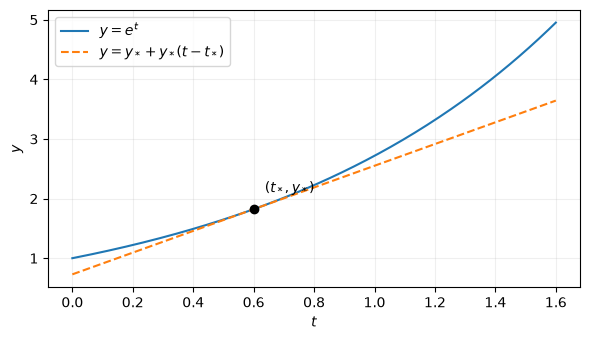

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1.6, 200)
t_star = 0.6
y_star = np.exp(t_star)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t, np.exp(t), label=r"$y=e^t$")
ax.plot(t, y_star * (1 + t - t_star), "--", label=r"$y=y_*+y_*(t-t_*)$")
ax.plot(t_star, y_star, "ko")
ax.annotate(r"$(t_*,y_*)$", (t_star, y_star), xytext=(8, 12), textcoords="offset points")
ax.set(xlabel="$t$", ylabel="$y$")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

*Рисунок 1. Наклон интегральной кривой в точке задается дифференциальным уравнением.*

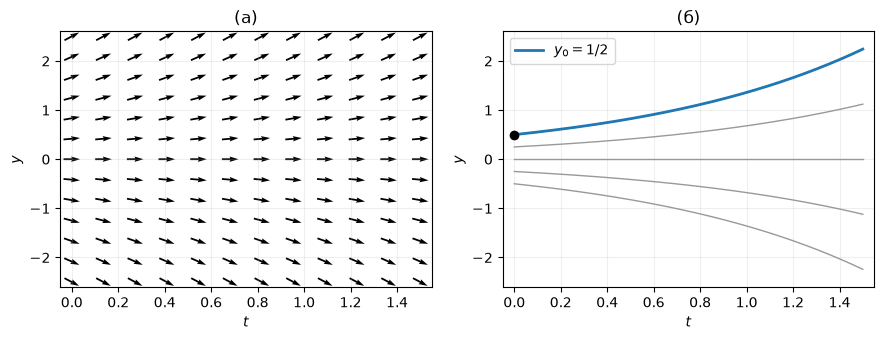

In [2]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1.5, 200)
T, Y = np.meshgrid(np.linspace(0, 1.5, 12), np.linspace(-2.5, 2.5, 13))
length = np.sqrt(1 + Y**2)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].quiver(T, Y, 1 / length, Y / length, angles="xy", pivot="mid")
for y0 in [-0.5, -0.25, 0, 0.25, 0.5]:
    axes[1].plot(t, y0 * np.exp(t), color="0.6", linewidth=1)
axes[1].plot(t, 0.5 * np.exp(t), color="tab:blue", linewidth=2, label=r"$y_0=1/2$")
axes[1].plot(0, 0.5, "ko")
axes[1].legend()
for letter, ax in zip(["(а)", "(б)"], axes):
    ax.set(xlabel="$t$", ylabel="$y$", title=letter, xlim=(-0.05, 1.55), ylim=(-2.6, 2.6))
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

*Рисунок 2. (а) Поле направлений; (б) интегральные кривые уравнения $y'=y$ и кривая, выделенная начальным условием.*

Геометрический смысл задания начального условия состоит в выделении из семейства интегральных кривых той кривой, которая проходит через фиксированную точку $(t_0,y_0)$.

**Определение 1 (задача Коши).** Задачу нахождения при $t>t_0$ решения $y(t)$ дифференциального уравнения (1), удовлетворяющего начальному условию (2), будем называть задачей Коши. В некоторых случаях представляет интерес поведение решения при всех $t>t_0$. Однако чаще ограничиваются определением решения на конечном отрезке $[t_0,T]$.

### Разрешимость задачи Коши

Пусть $\Pi_T$ — множество точек $(t,y)$, удовлетворяющих условиям $t_0\leqslant t\leqslant T$, $-\infty<y<\infty$; будем называть это множество полосой.

Приведем одну из теорем о разрешимости задачи Коши.

**Теорема 1 (существование и единственность).** Пусть функция $f(t,y)$ определена и непрерывна в полосе $\Pi_T$. Предположим также, что она удовлетворяет условию Липшица:

$$
|f(t, y_1) - f(t, y_2)| \leqslant L |y_1 - y_2| \tag{3}
$$

при всех $t_0\leqslant t\leqslant T$ и произвольных $y_1,y_2$, где $L$ — некоторая неотрицательная постоянная, называемая постоянной Липшица.

Тогда для каждого начального значения $y_0$ существует единственное решение $y(t)$ задачи Коши (1), (2), определенное на отрезке $[t_0,T]$.

**Замечание 1 (область применимости теоремы).** Постоянная Липшица едина для всех $t$ и всех $y\in\mathbb R$. Эти глобальные условия гарантируют существование на всем заданном отрезке. Локальное условие Липшица по $y$ дает локальное существование и единственность, но само по себе не исключает ухода решения на бесконечность за конечное время. Например, задача $y'=y^2$, $y(0)=1$ имеет решение $y(t)=1/(1-t)$ только до $t=1$.

**Замечание 2 (критерий через производную).** Для функций $f$, дифференцируемых по $y$, условие (3) выполняется тогда и только тогда, когда для всех $(t,y)\in\Pi_T$ справедливо неравенство

$$
|f'_y(t, y)| \leqslant L \tag{4}
$$

Поэтому условие (4) также можно называть условием Липшица.

**Замечание 3 (одностороннее условие Липшица).** Теорема 1 остается справедливой, если условие Липшица (3) заменить менее ограничительным односторонним условием Липшица

$$
\bigl(f(t, y_1) - f(t, y_2)\bigr)\,(y_1 - y_2) \leqslant \sigma (y_1 - y_2)^2. \tag{5}
$$

Постоянная $\sigma$ в этом условии может иметь любой знак.

Для функций $f$, дифференцируемых по $y$, условие (5) выполняется тогда и только тогда, когда для всех $(t,y)\in\Pi_T$ справедливо неравенство

$$
f'_y(t, y) \leqslant \sigma \tag{6}
$$

Для функции, удовлетворяющей условию Липшица с постоянной $L$, одностороннее условие автоматически выполняется с $\sigma=L$; иногда удается выбрать меньшую постоянную.

**Пример 1.** Функция $f(t,y)=\cos(t+y)$ удовлетворяет условию Липшица с постоянной $L=1$, поскольку $f_y'=-\sin(t+y)$ и $|f_y'|\leqslant1$. Поэтому решение задачи Коши $y'=\cos(t+y)$, $y(t_0)=y_0$ существует и единственно на любом отрезке $[t_0,T]$.

**Пример 2.** Функция $f(t,y)=t-y^3$ не удовлетворяет глобальному условию Липшица в полосе, поскольку $f_y'=-3y^2$ и модуль этой производной неограничен. В то же время одностороннее условие (6) выполняется с постоянной $\sigma=0$. Следовательно, решение задачи Коши $y'=t-y^3$, $y(t_0)=y_0$ существует и единственно на любом отрезке $[t_0,T]$.

**Пример 3.** Функция $f(t,y)=t+y^3$ не удовлетворяет одностороннему условию (6), поскольку частная производная $f_y'=3y^2$ неограничена сверху. Поэтому вопрос о разрешимости задачи Коши $y'=t+y^3$, $y(t_0)=y_0$ требует дополнительного исследования.

Одностороннее условие ограничивает расхождение решений, а не модуль $f_y'$. Вместе с непрерывностью на всей полосе оно также препятствует уходу решения на бесконечность за конечное время: полагая в (5) $y_2=0$, получаем $y f(t,y)\leqslant\sigma y^2+|y|\,|f(t,0)|$, а функция $f(t,0)$ ограничена на $[t_0,T]$.

Отметим полезное утверждение, связывающее гладкость решения с гладкостью правой части уравнения.

**Теорема 2 (гладкость решения).** Пусть функция $f$ имеет $m$ непрерывных производных ($m\geqslant1$) в окрестности полосы $\Pi_T$. Тогда, если функция $y$ является решением задачи Коши (1), (2) на отрезке $[t_0,T]$, она имеет на этом отрезке $m+1$ непрерывных производных.

Это утверждение непосредственно следует из возможности продифференцировать тождество $y'(t)\equiv f(t,y(t))$ не менее $m$ раз. $\square$

В дальнейшем будем предполагать, что функции $f$ и $y$ дифференцируемы столько раз, сколько требуется для рассматриваемого численного метода.

### Устойчивость решения задачи Коши на конечном отрезке

Этот вопрос важен для понимания поведения численных методов интегрирования дифференциальных уравнений. Сначала рассмотрим распространение погрешностей начальных значений. Пусть $y_0^*$ — возмущенное начальное значение, $\varepsilon_0=y_0-y_0^*$ — его погрешность, а $y^*(t)$ — решение соответствующей задачи Коши

$$
(y^*)'(t) = f(t, y^*(t)), \tag{7}
$$

$$
y^*(t_0) = y_0^*. \tag{8}
$$

Для следующего вывода дополнительно предположим, что $f_y'$ непрерывна. Вычтем уравнение (7) из уравнения (1) и воспользуемся формулой конечных приращений:

$$
\begin{aligned}
f(t,y)-f(t,y^*)&=\lambda(t)(y(t)-y^*(t)),\\
\lambda(t)&=\int_0^1 f_y'(t,y^*(t)+s(y(t)-y^*(t)))\,ds.
\end{aligned}\tag{9}
$$

Интегральная запись позволяет не выбирать промежуточные точки как функции от $t$. Из нее также следует, что при одностороннем условии Липшица $\lambda(t)\leqslant\sigma$.

В результате погрешность $\varepsilon(t)=y(t)-y^*(t)$ удовлетворяет дифференциальному уравнению

$$
\varepsilon'(t) = \lambda(t)\,\varepsilon(t) \tag{10}
$$

и начальному условию

$$
\varepsilon(t_0) = \varepsilon_0. \tag{11}
$$

Решение задачи (10), (11) имеет вид

$$
\varepsilon(t) = \varepsilon_0 \exp\left\{ \int_{t_0}^t \lambda(\tau)\, d\tau \right\}. \tag{12}
$$

Таким образом, величина

$$
C(t)=\exp\left\{\int_{t_0}^t\lambda(\tau)\,d\tau\right\}.\tag{13}
$$

играет роль коэффициента усиления погрешности задачи Коши.

Знак производной $f_y'$ существенно влияет на поведение погрешности $\varepsilon(t)$. Если $f_y'>0$, величина $C(t)$, а вместе с ней модуль ненулевой погрешности возрастают. Соответствующие интегральные кривые расходятся (рисунок 3а). Иначе ведет себя погрешность при $f_y'<0$: величины $C(t)$ и $|\varepsilon(t)|$ убывают, а интегральные кривые сближаются. Модуль возмущения начального значения уменьшается (рисунок 3б), но одна лишь отрицательность производной в каждой точке не гарантирует стремления погрешности к нулю при $t\to\infty$. Если производная $f_y'$ меняет знак, поведение погрешности может быть более сложным.

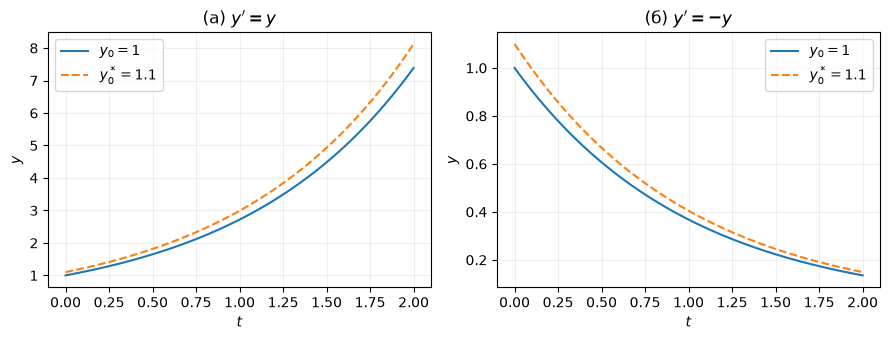

In [3]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, lam, title in zip(axes, [1, -1], [r"(а) $y'=y$", r"(б) $y'=-y$"]):
    ax.plot(t, np.exp(lam * t), label=r"$y_0=1$")
    ax.plot(t, 1.1 * np.exp(lam * t), "--", label=r"$y_0^*=1.1$")
    ax.set(xlabel="$t$", ylabel="$y$", title=title)
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

*Рисунок 3. Возмущения начальных данных возрастают для $y'=y$ и затухают для $y'=-y$.*

Выполнение одностороннего условия Липшица (5) гарантирует ограниченность коэффициента усиления $C(t)$ на конечном отрезке $[t_0,T]$. Действительно,

$$
\int_{t_0}^t \lambda(\tau)\, d\tau 
\leqslant \int_{t_0}^t \sigma\, d\tau 
= \sigma (t - t_0) \tag{14}
$$

Поэтому $C(t)\leqslant K(T)$ для всех $t_0\leqslant t\leqslant T$, где

$$
K(T) = 
\begin{cases}
e^{\sigma (T - t_0)}, & \text{при } \sigma > 0, \\
1, & \text{при } \sigma \leqslant 0.
\end{cases} \tag{15}
$$

Следовательно, при условии $f_y'\leqslant\sigma$ справедлива оценка

$$
\max_{t_0 \leqslant t \leqslant T} |y(t) - y^*(t)| \leqslant K(T)\,|y_0 - y_0^*|, \tag{16}
$$

выражающая устойчивость решения задачи Коши на конечном отрезке $[t_0,T]$ по начальным данным.

Эта оценка остается справедливой и без дифференцируемости $f$: ее можно получить непосредственно из одностороннего условия Липшица, оценивая разность двух решений.

### Модельное уравнение

Наиболее просто ведет себя погрешность при решении линейного уравнения

$$
y'(t) = \lambda\, y(t) + f(t) \tag{17}
$$

с постоянным вещественным коэффициентом $\lambda$ и непрерывной функцией $f(t)$, которая здесь не зависит от $y$. В этом случае погрешность $\varepsilon$ удовлетворяет уравнению $\varepsilon'=\lambda\varepsilon$ и задается формулой

$$
\varepsilon(t) = \varepsilon_0\, e^{\lambda (t - t_0)}. \tag{18}
$$

Поскольку функция $f(t)$ не влияет на характер распространения погрешности начального значения, при исследовании устойчивости по начальным данным естественно ограничиться случаем $f(t)\equiv0$ и рассматривать уравнение

$$
y'(t) = \lambda\, y(t). \tag{19}
$$

Уравнение (19) часто называют *модельным*. Оно играет важную роль в анализе численных методов решения задачи Коши.

Из формулы (18) следует, что при $\lambda\ne0$ за промежуток времени $\tau=1/|\lambda|$ модуль ненулевой погрешности увеличивается или уменьшается в $e$ раз. Поэтому величину $\tau=1/|\lambda|$ называют *постоянной времени* или *временным масштабом* модельного уравнения.

Для линейной модели можно также допустить комплексные значения $y$ и $\lambda$. Тогда временной масштаб роста или затухания модуля равен $\tau=1/|\operatorname{Re}\lambda|$ при $\operatorname{Re}\lambda\ne0$. Если $\operatorname{Re}\lambda=0$, модуль постоянен, поэтому конечного масштаба роста или затухания нет; ненулевая мнимая часть описывает колебания.

Предположим, что $f_y'$ непрерывна. При изучении распространения малого возмущения решения $y(t)$ уравнения $y'=f(t,y)$ в малой окрестности точки $\tilde t$ коэффициент $\lambda(t)$ в уравнении (10) близок к постоянной $\tilde\lambda=f_y'(\tilde t,y(\tilde t))$. Поэтому при $t\approx\tilde t$ приближенно выполняется $\varepsilon'(t)\approx\tilde\lambda\varepsilon(t)$. Следовательно, поведение погрешности для уравнения $y'=\tilde\lambda y$ моделирует локальное распространение погрешности для общего уравнения (1). Соответствующая постоянная времени называется *локальной постоянной времени*:

$$
\tau(\tilde t) = \dfrac{1}{|\tilde\lambda|}
= \dfrac{1}{|f'_y(\tilde t, y(\tilde t))|}. \tag{20}
$$

Эта величина меняется при изменении точки $\tilde t$. Локальный временной масштаб (20) используется при ненулевой производной. Замораживание коэффициента является локальным приближением, а не глобальной оценкой погрешности для нелинейного уравнения.

### Устойчивость по правой части

Будет ли решение задачи Коши устойчиво не только по погрешности $\varepsilon_0$ начального значения, но и по погрешности $\psi(t)$ задания правой части уравнения? Положительный ответ дает следующая теорема.

**Теорема 3 (возмущения начальных данных и правой части).** Пусть выполнены условия теоремы 1, а функция $\psi$ непрерывна на $[t_0,T]$. Пусть $y(t)$ — решение задачи (1), (2), а $y^*(t)$ — решение задачи

$$
(y^*)'(t) = f(t, y^*(t)) + \psi(t), \tag{21}
$$

$$
y^*(t_0) = y_0^*. \tag{22}
$$

Тогда справедлива оценка

$$
\max_{t_0 \leqslant t \leqslant T} |y(t) - y^*(t)| 
\leqslant K(T) \left( |y_0 - y_0^*| + \int_{t_0}^T |\psi(\tau)|\, d\tau \right), \tag{23}
$$

выражающая устойчивость решения задачи Коши на конечном отрезке $[t_0,T]$ по начальным данным и правой части. Здесь $K(T)=e^{L(T-t_0)}$.

**Замечание 4 (обусловленность).** Величина $K(T)$ является верхней оценкой абсолютного числа обусловленности задачи Коши. Если в теореме 1 условие Липшица (3) заменить односторонним условием (5), то оценка (23) выполняется с постоянной $K(T)$ из формулы (15).

Здесь возмущение правой части измеряется интегральной нормой $\int_{t_0}^T|\psi(\tau)|\,d\tau$. Если вместо нее использовать максимальный модуль, в оценке появляется дополнительный множитель $T-t_0$. Оценка $K(T)$ не обязательно точна.

### Устойчивость решения на неограниченном промежутке

Во многих прикладных задачах требуется изучать процессы, описываемые дифференциальными уравнениями, на больших промежутках времени. Поэтому важно понимать зависимость оценок устойчивости от длины отрезка. Если величина $K(T)$ в неравенстве (23) может неограниченно возрастать с увеличением $T$, такая оценка допускает экспоненциальный рост погрешности при $T\to\infty$ даже для сколь угодно малого возмущения $y_0$.

Сам по себе рост верхней оценки не доказывает роста каждого возмущения. Однако если задача действительно усиливает возмущения, для сохранения заданной точности на большом промежутке могут потребоваться все более точные исходные данные и вычисления.

**Пример 4.** Рассмотрим задачу Коши $y'=y-\sin t+\cos t$, $y(0)=0$. Ее решение, как легко проверить, имеет вид $y(t)=\sin t$.

Внесем погрешность в начальное значение, заменив условие $y(0)=0$ условием $y(0)=\varepsilon$. Решением соответствующей задачи будет $y(t)=\sin t+\varepsilon e^t$. Слагаемое погрешности $\varepsilon e^t$ быстро растет с увеличением $t$ и уже при умеренно больших $t$ может стать недопустимо большим (рисунок 4).

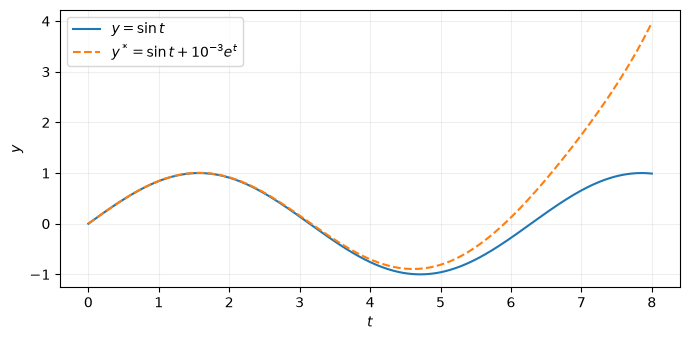

In [4]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 8, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, np.sin(t), label=r"$y=\sin t$")
ax.plot(t, np.sin(t) + 1e-3 * np.exp(t), "--", label=r"$y^*=\sin t+10^{-3}e^t$")
ax.set(xlabel="$t$", ylabel="$y$")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

*Рисунок 4. Решения $\sin t$ и $\sin t+\varepsilon e^t$ при $\varepsilon=10^{-3}$.*

Чтобы получить не зависящую от $T$ оценку усиления погрешности начального значения, достаточно потребовать $f_y'(t,y)\leqslant0$ для всех $t\geqslant t_0$ и всех $y$. При этом получается равномерная оценка и для возмущения правой части в интегральной норме. Однако равномерная оценка для постоянного внешнего возмущения в максимальной норме в общем случае не получается: для $y'=0$ и $\psi\equiv\delta$ погрешность растет как $|\delta|(t-t_0)$.

При строгом условии сжатия $f_y'(t,y)\leqslant\sigma<0$ справедлива оценка

$$
|y(t) - y^*(t)| \leqslant e^{\sigma (t - t_0)} |y_0 - y_0^*| 
+ \frac{1}{|\sigma|} \max_{t_0 \leqslant \tau \leqslant t} |\psi(\tau)|. \tag{24}
$$

Предположим, что $f$ непрерывна на $[t_0,\infty)\times\mathbb R$ и на каждой конечной полосе выполняется одностороннее условие с некоторой постоянной $\sigma(T)$. Тогда решения определены при всех $t\geqslant t_0$.

**Определение 2 (устойчивость по Ляпунову и асимптотическая устойчивость).** Зафиксируем $t_0$ и решение $y$. Рассмотрим решения $y^*$ того же невозмущенного дифференциального уравнения, то есть $\psi\equiv0$. Решение $y$ называется устойчивым по Ляпунову, если для каждого $\epsilon>0$ найдется $\delta>0$ такое, что из $|y_0-y_0^*|<\delta$ следует $|y(t)-y^*(t)|<\epsilon$ для всех $t\geqslant t_0$. Решение называется асимптотически устойчивым, если оно устойчиво по Ляпунову и для всех достаточно близких начальных значений $y^*(t)-y(t)\to0$ при $t\to\infty$.

**Утверждение 1 (достаточная оценка устойчивости).** Достаточным условием устойчивости по Ляпунову является оценка

$$
\sup_{t\geqslant t_0}|y(t)-y^*(t)|\leqslant K|y_0-y_0^*|,\tag{25}
$$

где $K$ не зависит от времени и от близкого начального значения. Это более сильная, липшицева форма непрерывной зависимости. Утверждение следует из выбора $\delta=\epsilon/(K+1)$. $\square$

**Замечание 5 (модельное уравнение).** Решения модельного уравнения (19) с вещественным параметром $\lambda$ устойчивы по Ляпунову тогда и только тогда, когда $\lambda\leqslant0$, и асимптотически устойчивы тогда и только тогда, когда $\lambda<0$. Это непосредственно следует из формулы (18).

Если параметр $\lambda$ комплексный, та же формула дает $|\varepsilon(t)|=|\varepsilon_0|e^{\operatorname{Re}\lambda(t-t_0)}$. Поэтому решения модельного уравнения устойчивы по Ляпунову тогда и только тогда, когда $\operatorname{Re}\lambda\leqslant0$, и асимптотически устойчивы тогда и только тогда, когда $\operatorname{Re}\lambda<0$.

**Следствие 1 (достаточное условие сжатия).** Для решения задачи Коши (1), (2) при $\psi\equiv0$ достаточным условием устойчивости по Ляпунову является неравенство $f_y'\leqslant0$. Условие $f_y'\leqslant\sigma$ с постоянной $\sigma<0$ обеспечивает асимптотическую устойчивость решения.

## Численные методы решения задачи Коши. Основные понятия и определения

### Сетки и сеточные функции

**Определение 3 (сетка и шаг сетки).** Первый шаг при построении численного метода решения задачи Коши состоит в замене отрезка $[t_0,T]$ — области непрерывного изменения аргумента $t$ — множеством $\overline\omega^h$, состоящим из конечного числа точек $t_0<t_1<\dots<t_N=T$ и называемым *сеткой*. Точки $t_n$ называются *узлами сетки*, а величина $h_n=t_n-t_{n-1}$ — *шагом сетки* (рисунок 5).

Для упрощения изложения обычно будем рассматривать равномерные сетки, у которых шаг $h_n$ постоянен. В этом случае $h_n=h=(T-t_0)/N$ и $t_n=t_0+nh$, $n=0,1,\ldots,N$.



*Рисунок 5. Неравномерная сетка сверху и равномерная сетка снизу.*

<details>
<summary>Рисунок 5: исходный код TikZ</summary>

```latex
\documentclass[tikz,border=8pt]{standalone}
\begin{document}
\begin{tikzpicture}[x=10cm,y=1cm]
  \draw[gray] (0,1.2) -- (1,1.2);
  \foreach \x/\label in {0/{t_0},0.12/{t_1},0.4/{t_2},0.55/{t_3},0.85/{t_4},1/{t_N=T}} {
    \fill[blue!65!black] (\x,1.2) circle (1.5pt);
    \node[below=5pt] at (\x,1.2) {$\label$};
  }
  \draw[<->] (0.4,1.55) -- node[above] {$h_3$} (0.55,1.55);
  \draw[gray] (0,0) -- (1,0);
  \foreach \x/\label in {0/{t_0},0.2/{t_1},0.4/{t_2},0.6/{t_3},0.8/{t_4},1/{t_N=T}} {
    \fill[blue!65!black] (\x,0) circle (1.5pt);
    \node[below=5pt] at (\x,0) {$\label$};
  }
  \draw[<->] (0.2,0.35) -- node[above] {$h$} (0.4,0.35);
\end{tikzpicture}
\end{document}
```

</details>

**Определение 4 (сеточная функция).** Наряду с функциями непрерывного аргумента будем рассматривать сеточные функции, определенные только в узлах сетки $\overline\omega^h$.

Чтобы отличать сеточные функции от функций непрерывного аргумента, будем указывать индекс узла. Например, $u_n$ обозначает значение сеточной функции в узле $t_n$. Для краткости значения $u^h(t_n)$ сеточной функции $u^h$ будем обозначать через $u_n^h$.

### Дискретная задача Коши

Следующий шаг при построении численного метода состоит в замене задачи Коши ее дискретным аналогом — системой уравнений, решение которой позволяет последовательно вычислить значения $y_1,y_2,\ldots,y_N$ сеточной функции $y^h$, приближающие значения решения в узлах сетки $\overline\omega^h$.

Построение конкретного численного метода основывается на некотором способе замены дифференциального уравнения $y'=f(t,y)$ его дискретным аналогом — уравнением вида

$$
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y_{n+1-j}
= \Phi(t_n, y_{n+1-k}, \ldots, y_n, y_{n+1}, h), \tag{26}
$$

В него входят значения сеточной функции $y^h$ в $k+1$ последовательных точках $t_{n+1-k},\ldots,t_n,t_{n+1}$. Здесь $k\geqslant1$ фиксировано, $N\geqslant k$, вещественные коэффициенты $\alpha_j$ не зависят от $h$, а $\alpha_0\ne0$. Рассматриваются положительные шаги $h=(T-t_0)/N$. Для неявных схем дополнительно требуется разрешимость каждого шага.

Во всех рассматриваемых далее методах выражение

$$
\frac{1}{h}
\left( \alpha_0 y_{n+1} + \alpha_1 y_n + \ldots + \alpha_k y_{n+1-k} \right) \tag{27}
$$

в левой части (26) можно рассматривать как разностную аппроксимацию производной $y'$ согласно одной из формул численного дифференцирования. Правую часть $\Phi$ можно рассматривать как специально построенную аппроксимацию функции $f$.

Из уравнения (26) находится значение $y_{n+1}$ — приближение решения в следующем узле. При этом используются ранее вычисленные значения сеточной функции в точках $t_{n+1-k},\ldots,t_n$.

**Определение 5 (число шагов и дискретная задача Коши).** Такие методы называются *$k$-шаговыми*. Для вычисления сеточной функции $y^h$ с помощью $k$-шагового метода требуется задать $k$ начальных значений:

$$
y^h(t_0) = y_0,\quad
y^h(t_1) = y_1,\quad
\ldots,\quad
y^h(t_{k-1}) = y_{k-1}. \tag{28}
$$

Задачу вычисления сеточной функции $y^h$, удовлетворяющей уравнению (26) при $n=k-1,\ldots,N-1$ и принимающей заданные начальные значения (28), будем называть *дискретной задачей Коши*.

**Замечание 6.** Уравнение (26) принято считать определяющим численный метод решения задачи Коши. В дальнейшем будем отождествлять свойства численного метода, дискретного уравнения (26) и соответствующей дискретной задачи Коши.

**Определение 6 (одношаговые и многошаговые методы).** При $k=1$ используем нормированную форму $\alpha_0=1$, $\alpha_1=-1$; условия нормировки обсуждаются ниже. Тогда уравнение (26) принимает вид

$$
\frac{y_{n+1} - y_n}{h} = \Phi(t_n, y_n, y_{n+1}, h). \tag{29}
$$

Соответствующий метод называется *одношаговым*. Для вычисления $y_{n+1}$ используется только одно предыдущее значение $y_n$. Поэтому одношаговые методы часто называют самостартующими. Метод, требующий $k>1$ предыдущих значений, называется *многошаговым*. Дополнительные стартовые значения необходимо вычислить отдельно, например одношаговым методом.

**Пример 5.** Простейшим дискретным аналогом дифференциального уравнения (1) является

$$
\frac{y_{n+1} - y_n}{h} = f(t_n, y_n), \tag{30}
$$

Он приводит к известному методу Эйлера.

**Пример 6.** Метод Эйлера является одношаговым. Следующее значение $y_{n+1}$ вычисляется по формуле

$$
y_{n+1} = y_n + h f(t_n, y_n). \tag{31}
$$



### Явные и неявные методы

Реализация численного метода на компьютере требует построения алгоритма, позволяющего вычислить решение дискретной задачи Коши.

**Определение 7 (явные и неявные методы).** Если функция $\Phi$ в уравнении (26) не зависит от $y_{n+1}$, значение $y_{n+1}$ вычисляется по явной формуле

$$
y_{n+1}
= \alpha_0^{-1} \left[
- \sum_{j=1}^k \alpha_j\, y_{n+1-j}
+ h\, \Phi(t_n, y_{n+1-k}, \ldots, y_n, h)
\right]. \tag{32}
$$

Соответствующие методы называются *явными*. Напротив, методы, у которых функция $\Phi$ зависит от $y_{n+1}$, называются *неявными*. При реализации неявного метода на каждом шаге требуется решить относительно $y_{n+1}$ уравнение (26), в общем случае нелинейное.

**Пример 7.** Метод Эйлера, в котором $y_{n+1}$ вычисляется по явной формуле (31), является явным методом.

**Пример 8.** Простейший пример неявного метода — *неявный метод Эйлера*, соответствующий аппроксимации дифференциального уравнения (1) дискретным уравнением

$$
\frac{y_{n+1} - y_n}{h} = f(t_{n+1}, y_{n+1}). \tag{33}
$$

Другой пример неявного метода — *метод трапеций*:

$$
\frac{y_{n+1} - y_n}{h} =
\frac{1}{2}\, \bigl( f(t_n, y_n) + f(t_{n+1}, y_{n+1}) \bigr). \tag{34}
$$

В обоих методах значение $y_{n+1}$ задается неявно. Для нелинейной $f$ обычно требуется итерационный метод; для линейной $f$ значение может быть найдено непосредственно.

**Замечание 7 (разрешимость неявного шага).** Если при фиксированных предыдущих значениях функция $\Phi$ глобально липшицева по $y_{n+1}$ с постоянной $M$, то условие $hM<|\alpha_0|$ достаточно для единственности решения шага по принципу сжимающих отображений. Это достаточное, а не необходимое условие. Для неявного метода Эйлера при $f(t,y)=\lambda y$ и $\lambda\leqslant0$ знаменатель $1-h\lambda$ отличен от нуля при любом $h>0$.

### Устойчивость

Если решение дискретной задачи Коши неустойчиво относительно малых возмущений начальных значений и правой части уравнения, соответствующий численный метод нельзя надежно использовать в вычислениях. Дадим определение устойчивости, достаточное для дальнейшего изложения.

Внесем в правую часть уравнения (26) произвольные малые возмущения $\psi_n$, а в начальные условия (28) — возмущения $\varepsilon_0,\varepsilon_1,\ldots,\varepsilon_{k-1}$. Пусть

$$
y_0^* = y_0 - \varepsilon_0,\quad
y_1^* = y_1 - \varepsilon_1,\quad \ldots,\quad
y_{k-1}^* = y_{k-1} - \varepsilon_{k-1}.\tag{35}
$$

Обозначим через $y_n^{*\,h}$ решение соответствующей возмущенной задачи

$$
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y_{n+1-j}^*
= \Phi(t_n, y_{n+1-k}^*, \ldots, y_n^*, y_{n+1}^*, h)
+ \psi_n, \tag{36}
$$

$$
y^{*\,h}(t_0) = y_0^*,\;
y^{*\,h}(t_1) = y_1^*,\; \ldots,\;
y^{*\,h}(t_{k-1}) = y_{k-1}^*. \tag{37}
$$

**Определение 8 (устойчивость на конечном отрезке).** Дискретную задачу Коши (26), (28) и соответствующий численный метод будем называть *устойчивыми на конечном отрезке* или просто *устойчивыми*, если для всех допустимых $0<h\leqslant h_0$ при достаточно малом $h_0$ и всех достаточно малых возмущений, для которых решения существуют, выполняется неравенство

$$
\max_{0 \leqslant n \leqslant N} |y_n - y_n^{*\,h}|
\leqslant \widetilde{K}(T) \left(
\max_{0 \leqslant s \leqslant k-1} |\varepsilon_s|
\;+\; \sum_{n = k-1}^{N-1} |\psi_n| \cdot h
\right), \tag{38}
$$

Здесь величина $\widetilde K(T)$ не зависит от $h$, от $\varepsilon_s$ при $0\leqslant s\leqslant k-1$ и от $\psi_n$ при $k-1\leqslant n\leqslant N-1$.

**Замечание 8.** Неравенство (38) является дискретным аналогом неравенства (23), выражающего устойчивость решения непрерывной задачи Коши. Для одношаговых методов, то есть при $k=1$, неравенство (38) принимает вид

$$
\max_{0 \leqslant n \leqslant N} |y_n - y_n^{*\,h}|
\leqslant \widetilde{K}(T) \left(
|\varepsilon_0|
+ \sum_{n = 0}^{N-1} |\psi_n| \cdot h
\right), \tag{39}
$$

Аналогия с (23) становится еще более наглядной. Действительно, сумма

$$
\sum_{n=0}^{N-1} |\psi_n| \cdot h\tag{40}
$$

может рассматриваться как дискретный аналог интеграла

$$
\int_{t_0}^T |\psi(t)|\, dt,\tag{41}
$$

построенный по формуле левых прямоугольников.

Данное определение относится к фиксированному конечному моменту $T$ и равномерной по $h\to0$ оценке. Его следует отличать от абсолютной устойчивости, при которой исследуется поведение метода при фиксированном $h\lambda$ на сколь угодно большом числе шагов. Устойчивая непрерывная задача не обязательно корректно воспроизводится методом при произвольном шаге.

### Аппроксимация

Пусть $y(t)$ — произвольная гладкая функция. Рассмотрим внутренние узлы $t=t_n$, для которых весь шаблон лежит в $[t_0,T]$, и устремим $h$ к нулю по допустимым сеткам. Для последующих оценок погрешности требуется равномерная по таким узлам сходимость.

Предположим, что замена в формуле (27) значений $y_{n+1-j}$ сеточной функции $y^h$ соответствующими значениями $y(t-(j-1)h)$ функции $y$ дает величину

$$
\frac{1}{h}
\left( \alpha_0 y(t + h) + \alpha_1 y(t) + \ldots + \alpha_k y\bigl(t - (k - 1)h\bigr) \right), \tag{42}
$$

стремящуюся к $y'(t)$ при $h\to0$.

Аналогично предположим, что

$$
\Phi\bigl(t,\,
y(t - (k - 1)h), \ldots, y(t), y(t + h), h\bigr)
\;\longrightarrow\;
f(t, y(t)) \quad \text{при } h \to 0. \tag{43}
$$

**Утверждение 2 (нормировка разностного оператора).** Из этих предположений следует, что коэффициенты $\alpha_0,\alpha_1,\ldots,\alpha_k$ должны удовлетворять условиям

$$
\sum_{j=0}^k\alpha_j=0,\quad\sum_{j=0}^k(1-j)\alpha_j=1. \tag{44}
$$

**Доказательство.** При $y(t)\equiv1$ величина (42) равна $\overline\alpha/h$, где $\overline\alpha=\sum_{j=0}^k\alpha_j$. По предположению, $\overline\alpha/h\to y'(t)=0$ при $h\to0$. Это возможно только при $\overline\alpha=0$, что доказывает первое равенство в (44). Подстановка $y(t)=t$ в (42) затем дает $\sum_{j=0}^k(1-j)\alpha_j=1$, то есть второе равенство. $\square$

Пусть $y(t)$ — решение задачи Коши (1), (2).

**Определение 9 (погрешность аппроксимации).** Сеточную функцию $\psi_n^h$, определяемую формулой

$$
\psi_n^h =
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y(t_{n+1-j})
- \Phi\bigl(t_n, y(t_{n+1-k}), \ldots, y(t_n), y(t_{n+1}), h\bigr),
\tag{45}
$$

будем называть *погрешностью аппроксимации* дискретного уравнения (26) на решении $y$. Запись этой формулы в виде

$$
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y(t_{n+1-j})
= \Phi\bigl(t_n, y(t_{n+1-k}), \ldots, y(t_n), y(t_{n+1}), h\bigr)
+ \psi_n^h, \tag{46}
$$

показывает, что точное решение $y(t)$ удовлетворяет уравнению (26) с точностью до погрешности аппроксимации $\psi_n^h$.

Сеточная функция $\psi_n^h$ позволяет предварительно оценить, насколько точно дифференциальное уравнение заменяется дискретным аналогом.

**Определение 10 (аппроксимация и ее порядок).** Будем говорить, что численный метод (26) *аппроксимирует дифференциальное уравнение (1)*, если

$$
\max_{k-1 \leqslant n \leqslant N-1} |\psi_n^h| \to 0 \quad \text{при } h \to 0, \tag{47}
$$

и аппроксимирует его *с порядком $p$*, если справедлива оценка

$$
\max_{k-1 \leqslant n \leqslant N-1} |\psi_n^h|
\leqslant C h^p,\quad p > 0, \tag{48}
$$

где $C$ не зависит от $h$ и номера узла, а шаг достаточно мал и допустим.

**Определение 11 (локальная погрешность).** Для одношаговых методов (29) вместо погрешности аппроксимации часто используют другую величину — локальную погрешность. Пусть $y_{n+1}$ — значение, полученное из уравнения

$$
\frac{y_{n+1} - y(t_n)}{h}
= \Phi\bigl(t_n, y(t_n), y_{n+1}, h\bigr), \tag{49}
$$

то есть из уравнения (29), в котором $y_n$ заменено точным значением решения в точке $t_n$.

Разность $l_n=y(t_{n+1})-y_{n+1}$ называется *локальной погрешностью метода* или *погрешностью одного шага*. Она измеряет ошибку одного шага при точных входных данных.

Для явного одношагового метода $\Phi$ не зависит от аргумента, соответствующего новому значению решения, поэтому из определений следует

$$
l_n=h\psi_n^h.\tag{50}
$$

Для неявного метода соответствующее тождество имеет вид

$$
l_n=h\psi_n^h+h\bigl[\Phi(t_n,y(t_n),y(t_{n+1}),h)-\Phi(t_n,y(t_n),y_{n+1},h)\bigr].\tag{51}
$$

Если $\Phi$ липшицева по новому значению с постоянной $M$, не зависящей от $h$, и $hM<1$, то

$$
\frac{h|\psi_n^h|}{1+hM}\leqslant |l_n|\leqslant\frac{h|\psi_n^h|}{1-hM}.\tag{52}
$$

Таким образом, при указанных условиях погрешность аппроксимации $O(h^p)$ дает локальную погрешность $O(h^{p+1})$. Порядок аппроксимации $p$ не определяет, является метод явным или неявным.

### Сходимость

Пусть $y(t)$ — решение задачи Коши.

**Определение 12 (глобальная погрешность).** *Глобальной погрешностью* или просто *погрешностью* численного метода называется сеточная функция $\varepsilon^h$ со значениями $\varepsilon_n=y(t_n)-y_n$ в узлах сетки. В качестве меры абсолютной погрешности метода примем величину

$$
E(h) = \max_{0 \leqslant n \leqslant N} |y(t_n) - y_n|. \tag{53}
$$

**Определение 13 (сходимость и порядок точности).** Численный метод решения задачи Коши называется *сходящимся*, если $E(h)\to0$ при $h\to0$. Говорят, что метод *сходится с порядком $p$* или имеет *порядок точности $p$*, если $E(h)\leqslant Ch^p$, $p>0$, при всех достаточно малых допустимых $h$ с постоянной $C$, не зависящей от $h$.

Покажем, что для устойчивого численного метода наличие аппроксимации порядка $p$ обеспечивает сходимость того же порядка. Предположим, что начальные значения $y_0,y_1,\ldots,y_{k-1}$ заданы с точностью порядка $p$:

$$
\max_{0 \leqslant n \leqslant k-1} |y(t_n) - y_n| \leqslant C_0 h^p. \tag{54}
$$

**Теорема 4 (устойчивость и аппроксимация обеспечивают сходимость).** Пусть численный метод устойчив на конечном отрезке и имеет порядок аппроксимации $p$. Предположим, что точное сеточное решение и численное решение лежат в области применимости оценки устойчивости с постоянными, едиными по $h$. Тогда, если начальные значения $y_0,\ldots,y_{k-1}$ заданы с точностью порядка $p$, метод сходится с порядком $p$.

**Доказательство.** Обозначим через $\psi_n$ погрешность аппроксимации и положим $y_n^*=y(t_n)$. Из равенства (45) следует, что сеточная функция $y_n^*$ является решением возмущенной дискретной задачи (36), (37). Устойчивость метода дает неравенство (38), которое с учетом $y_n^*=y(t_n)$ принимает вид

$$
\begin{gathered}
\max_{0 \leqslant n \leqslant N} |y(t_n) - y_n|\leqslant\\
\leqslant \widetilde{K}(T)
\left(
\max_{0 \leqslant s \leqslant k-1} |y(t_s) - y_s|
+ \sum_{n=k-1}^{N-1} |\psi_n| \cdot h
\right).
\end{gathered}
\tag{55}
$$

Поскольку

$$
\sum_{n=k-1}^{N-1} |\psi_n| \cdot h
\leqslant (T - t_0) \max_{k-1 \leqslant n \leqslant N-1} |\psi_n|
\leqslant (T - t_0)\, C h^p, \tag{56}
$$

правая часть (55) оценивается величиной

$$
\widetilde{K}(T)\, \left( C_0 + (T - t_0) C \right) h^p. \tag{57}
$$

Следовательно,

$$
\max_{0 \leqslant n \leqslant N} |y(t_n) - y_n|
\leqslant C_1 h^p, \tag{58}
$$

что доказывает сходимость метода с порядком $p$. $\square$

### Связь с задачей вычисления интеграла

Существует тесная связь между задачей Коши и задачей вычисления интеграла с переменным верхним пределом:

$$
y(t) = \int_{t_0}^{t} f(\tau)\, d\tau,\quad t_0 \leqslant t \leqslant T. \tag{59}
$$

Действительно, вычисление интеграла (59) равносильно решению задачи Коши

$$
y'(t) = f(t),\quad y(t_0) = 0, \tag{60}
$$

которая является частным случаем более общей задачи (1), (2).

Таким образом, каждый численный метод решения задачи Коши порождает соответствующий метод численного интегрирования. Например, метод Эйлера $y_{n+1}=y_n+hf(t_n)$ приводит к *формуле левых прямоугольников*:

$$
y(t_n) \approx y_n = h \sum_{i=0}^{n-1} f(t_i). \tag{61}
$$

Неявный метод Эйлера $y_{n+1}=y_n+hf(t_{n+1})$ дает *формулу правых прямоугольников*:

$$
y(t_n) \approx y_n = h \sum_{i=1}^{n} f(t_i). \tag{62}
$$

Метод трапеций (34) приводит к известной *квадратурной формуле трапеций*:

$$
y(t_n) \approx \frac{h}{2} \sum_{i=1}^{n} \bigl( f(t_{i-1}) + f(t_i) \bigr). \tag{63}
$$

На примере формулы (61) легко увидеть разницу между локальной и глобальной погрешностями. Локальная погрешность — это погрешность на одном элементарном отрезке:

$$
l_n = \int_{t_n}^{t_{n+1}} f(t)\, dt - h f(t_n), \tag{64}
$$

Глобальная погрешность — это накопленная погрешность:

$$
\varepsilon_n = \int_{t_0}^{t_n} f(t)\, dt - h \sum_{i=0}^{n-1} f(t_i). \tag{65}
$$

В данном случае, поскольку правая часть не зависит от $y$, глобальная погрешность равна сумме локальных:

$$
\varepsilon_n = \sum_{\ell=0}^{n-1} l_\ell. \tag{66}
$$

Если $f$ зависит от $y$, глобальная погрешность в общем случае уже не равна невзвешенной сумме локальных погрешностей, даже для линейного уравнения $y'=\lambda y$. При распространении локальные ошибки могут усиливаться (рисунок 6а) или затухать (рисунок 6б). Их знаки и возможная компенсация также имеют значение.

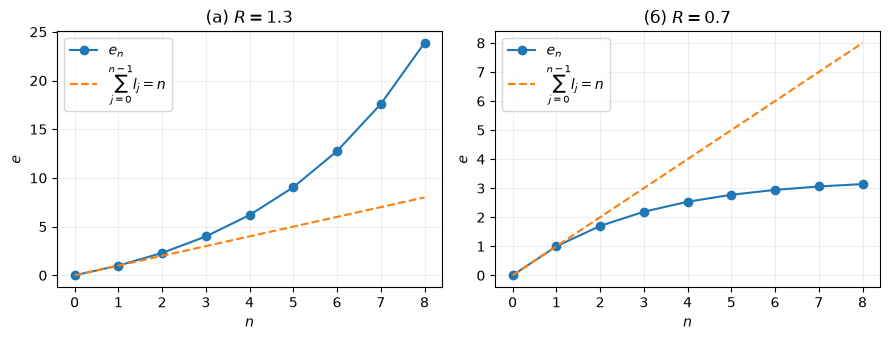

In [5]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(9)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, R, title in zip(axes, [1.3, 0.7], [r"(а) $R=1.3$", r"(б) $R=0.7$"]):
    # Каждая локальная погрешность равна единице; ее вклад распространяется с множителем R.
    e = np.zeros(len(n))
    for j in range(len(n) - 1):
        e[j + 1] = R * e[j] + 1
    ax.plot(n, e, "o-", label=r"$e_n$")
    ax.plot(n, n, "--", label=r"$\sum_{j=0}^{n-1}l_j=n$")
    ax.set(xlabel="$n$", ylabel="$e$", title=title)
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

*Рисунок 6. Вклады $l_j$ в скалярную рекуррентную формулу погрешности $e_{j+1}=Re_j+l_j$: усиление при $R>1$ и затухание при $0<R<1$ для одинаковых положительных локальных погрешностей.*

**Пример 9 (проверка порядков погрешности).** Для задачи $y'=y$, $y(0)=1$ явный метод Эйлера, начатый с точного значения, дает

$$
\begin{aligned}
\psi_n^h&=e^{t_n}\left(\frac{e^h-1}{h}-1\right)=\tfrac12 e^{t_n}h+O(h^2),\\
l_n&=e^{t_n}(e^h-1-h)=\tfrac12 e^{t_n}h^2+O(h^3).
\end{aligned}\tag{67}
$$

В точке $T=1$ положим $h=1/N$. Метод Эйлера дает $y_N=(1+h)^N$, поэтому

$$
y(1)-y_N=e-(1+h)^{1/h}=\frac e2h+O(h^2).\tag{68}
$$

Локальная погрешность имеет второй порядок по $h$, а глобальная — первый. Поэтому уменьшение шага вдвое асимптотически уменьшает глобальную погрешность вдвое, а не в четыре раза.

## Литература

1. **E. Hairer, S. P. Nørsett, G. Wanner.** *Solving Ordinary Differential Equations I: Nonstiff Problems.* 2nd revised edition. Springer, 1993. Задача Коши, локальные погрешности, устойчивость и сходимость.
2. **J. C. Butcher.** *Numerical Methods for Ordinary Differential Equations.* 3rd edition. Wiley, 2016. Одношаговые и многошаговые методы.
3. **A. Iserles.** *A First Course in the Numerical Analysis of Differential Equations.* 2nd edition. Cambridge University Press, 2009. Дискретизация, распространение погрешностей и устойчивость.